<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/ireland-fuel-grocery-viz%20/notebooks/02_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Load clean data directly from your GitHub repository
data_url = "https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/refs/heads/main/data/cleaned_fuel_grocery_data.csv"
df = pd.read_csv(data_url)

# Convert Month to datetime format for plotting
df["Month_DT"] = pd.to_datetime(df["Month_DT"])

# Sort chronologically
df = df.sort_values("Month_DT").reset_index(drop=True)

df.head()

,Month,Diesel,Food and non-alcoholic beverages,Petrol,Month_DT,Month_Diff
0,2016 January,65.0,90.7,72.8,2016-01-01,NaN
1,2016 February,61.1,90.0,70.5,2016-02-01,31 days
2,2016 March,61.9,90.3,70.0,2016-03-01,29 days
3,2016 April,64.2,90.0,73.1,2016-04-01,31 days
4,2016 May,65.3,90.0,74.7,2016-05-01,30 days


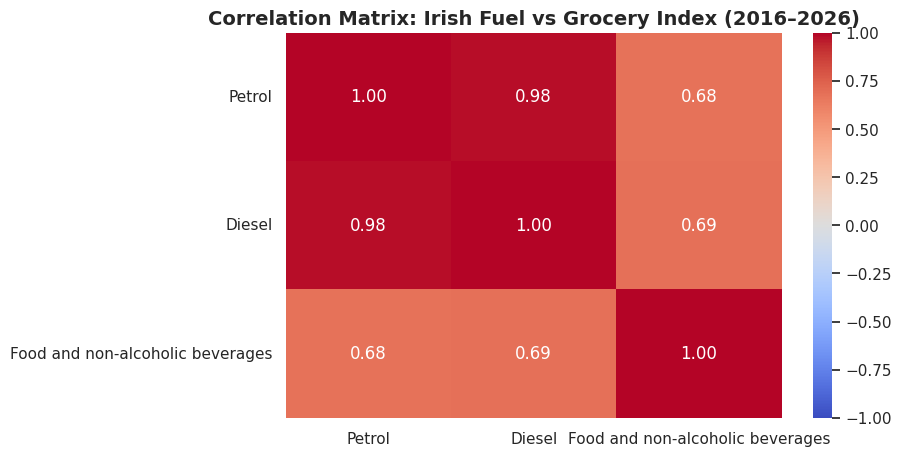

In [7]:
# Select core numerical variables
cols_to_correlate = ["Petrol", "Diesel", "Food and non-alcoholic beverages"]

# Compute Pearson correlation matrix
corr = df[cols_to_correlate].corr()

# Plot Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix: Irish Fuel vs Grocery Index (2016–2026)", fontsize=14, fontweight="bold")
plt.show()

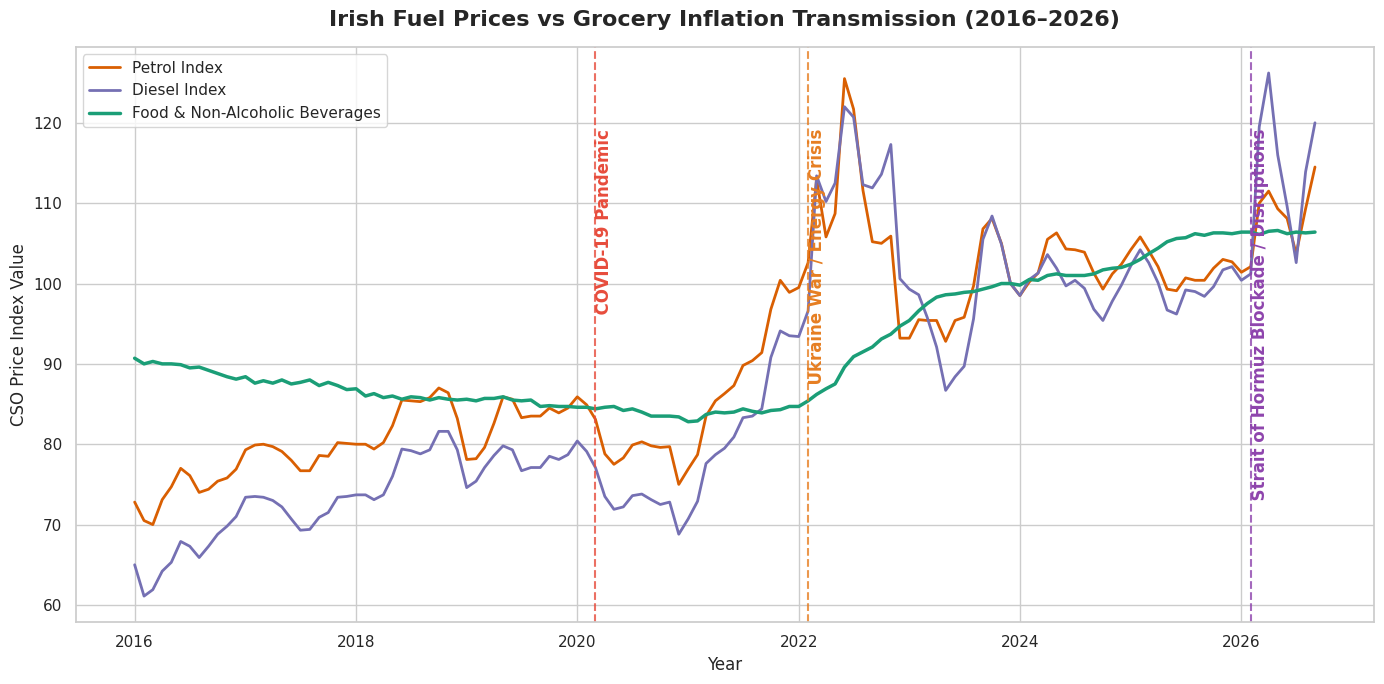

In [9]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.figure(figsize=(14, 7))

# Plot line charts
plt.plot(
    df["Month_DT"],
    df["Petrol"],
    label="Petrol Index",
    color="#d95f02",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Diesel"],
    label="Diesel Index",
    color="#7570b3",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Food and non-alcoholic beverages"],
    label="Food & Non-Alcoholic Beverages",
    color="#1b9e77",
    linewidth=2.5,
)

# Milestone Events (Vertical lines & labels with updated 2026 date)
events = [
    ("2020-03-01", "COVID-19 Pandemic", "#e74c3c"),
    ("2022-02-01", "Ukraine War / Energy Crisis", "#e67e22"),
    ("2026-02-01", "Strait of Hormuz Blockade / Disruptions", "#8e44ad"),
]

for date_str, label, col in events:
    event_date = pd.to_datetime(date_str)
    plt.axvline(
        x=event_date, color=col, linestyle="--", alpha=0.8, linewidth=1.5
    )
    plt.text(
        event_date,
        df["Petrol"].max() * 0.95,
        f"  {label}",
        color=col,
        fontweight="bold",
        rotation=90,
        verticalalignment="top",
    )

# Formatting
plt.title(
    "Irish Fuel Prices vs Grocery Inflation Transmission (2016–2026)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("CSO Price Index Value", fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()

plt.show()

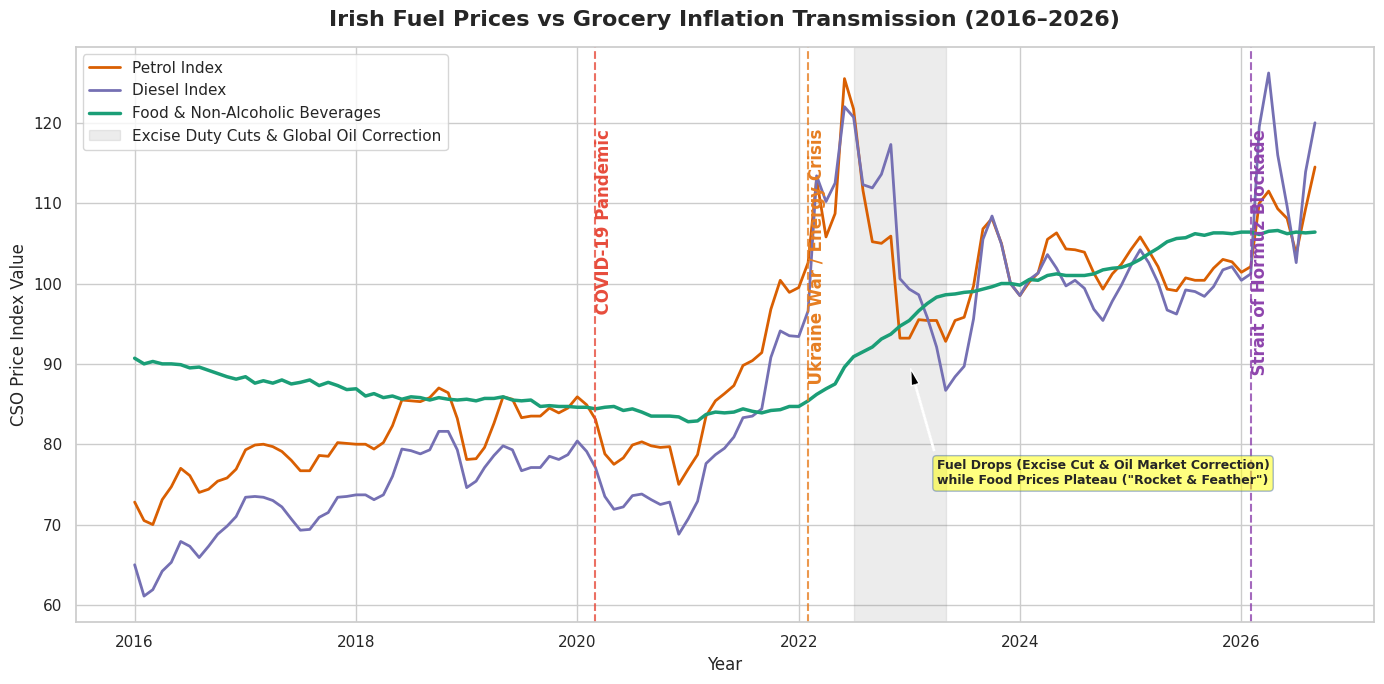

In [10]:
plt.figure(figsize=(14, 7))

# Plot lines
plt.plot(df['Month_DT'], df['Petrol'], label='Petrol Index', color='#d95f02', linewidth=2)
plt.plot(df['Month_DT'], df['Diesel'], label='Diesel Index', color='#7570b3', linewidth=2)
plt.plot(df['Month_DT'], df['Food and non-alcoholic beverages'], label='Food & Non-Alcoholic Beverages', color='#1b9e77', linewidth=2.5)

# Highlight the 2022-2023 Fuel Price Drop & Policy Cut
plt.axvspan(pd.to_datetime('2022-07-01'), pd.to_datetime('2023-05-01'), color='gray', alpha=0.15, label='Excise Duty Cuts & Global Oil Correction')

# Milestone Lines
events = [
    ('2020-03-01', 'COVID-19 Pandemic', '#e74c3c'),
    ('2022-02-01', 'Ukraine War / Energy Crisis', '#e67e22'),
    ('2026-02-01', 'Strait of Hormuz Blockade', '#8e44ad')
]

for date_str, label, col in events:
    event_date = pd.to_datetime(date_str)
    plt.axvline(x=event_date, color=col, linestyle='--', alpha=0.8, linewidth=1.5)
    plt.text(event_date, df['Petrol'].max()*0.95, f'  {label}', color=col, fontweight='bold', rotation=90, verticalalignment='top')

# Text annotation pointing to the divergence
plt.annotate('Fuel Drops (Excise Cut & Oil Market Correction)\nwhile Food Prices Plateau ("Rocket & Feather")',
             xy=(pd.to_datetime('2023-01-01'), 90),
             xytext=(pd.to_datetime('2023-04-01'), 75),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontweight='bold', fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="b", lw=1, alpha=0.5))

plt.title('Irish Fuel Prices vs Grocery Inflation Transmission (2016–2026)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('CSO Price Index Value', fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

plt.show()

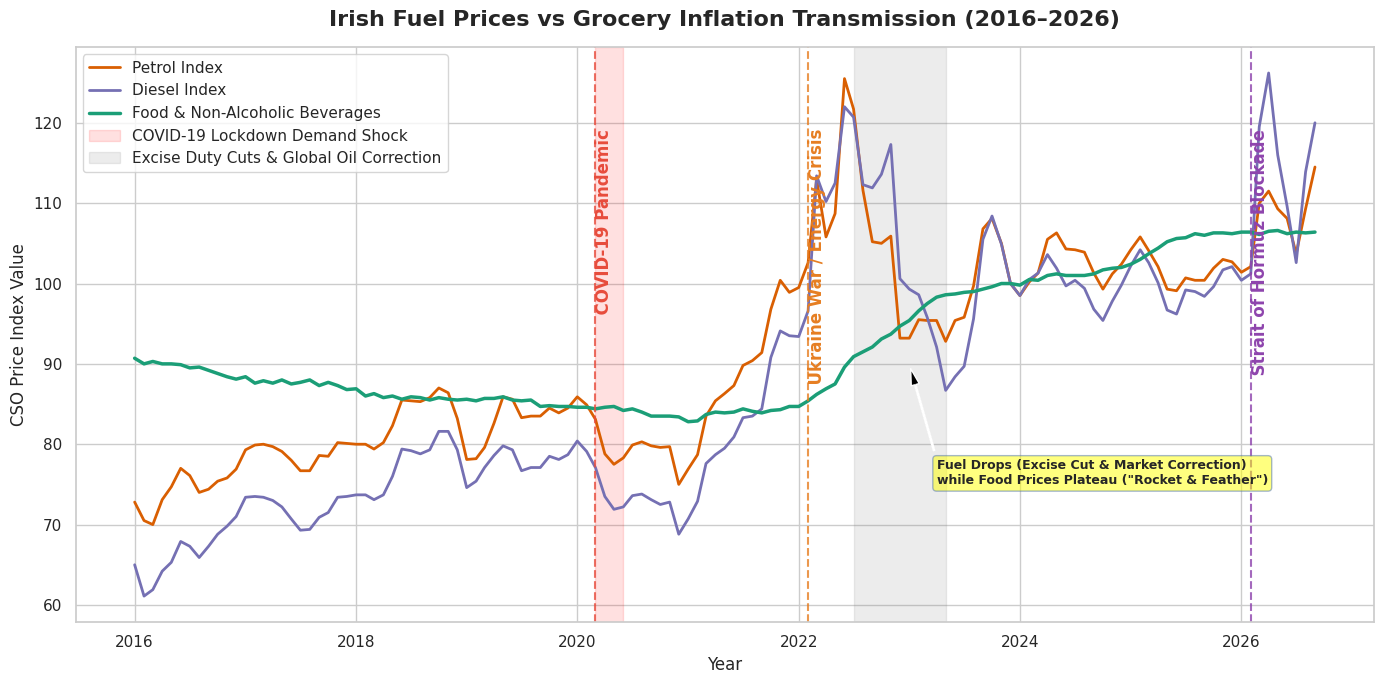

In [11]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.figure(figsize=(14, 7))

# 1. Plot Core Variables
plt.plot(
    df["Month_DT"],
    df["Petrol"],
    label="Petrol Index",
    color="#d95f02",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Diesel"],
    label="Diesel Index",
    color="#7570b3",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Food and non-alcoholic beverages"],
    label="Food & Non-Alcoholic Beverages",
    color="#1b9e77",
    linewidth=2.5,
)

# 2. Shaded Event Spans (Highlighting the major price drops)
plt.axvspan(
    pd.to_datetime("2020-03-01"),
    pd.to_datetime("2020-06-01"),
    color="red",
    alpha=0.12,
    label="COVID-19 Lockdown Demand Shock",
)
plt.axvspan(
    pd.to_datetime("2022-07-01"),
    pd.to_datetime("2023-05-01"),
    color="gray",
    alpha=0.15,
    label="Excise Duty Cuts & Global Oil Correction",
)

# 3. Geopolitical Shock Milestone Lines
events = [
    ("2020-03-01", "COVID-19 Pandemic", "#e74c3c"),
    ("2022-02-01", "Ukraine War / Energy Crisis", "#e67e22"),
    ("2026-02-01", "Strait of Hormuz Blockade", "#8e44ad"),
]

for date_str, label, col in events:
    event_date = pd.to_datetime(date_str)
    plt.axvline(
        x=event_date, color=col, linestyle="--", alpha=0.8, linewidth=1.5
    )
    plt.text(
        event_date,
        df["Petrol"].max() * 0.95,
        f"  {label}",
        color=col,
        fontweight="bold",
        rotation=90,
        verticalalignment="top",
    )

# 4. Text Annotations for Asymmetric Transmission
plt.annotate(
    'Fuel Drops (Excise Cut & Market Correction)\nwhile Food Prices Plateau ("Rocket & Feather")',
    xy=(pd.to_datetime("2023-01-01"), 90),
    xytext=(pd.to_datetime("2023-04-01"), 75),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontweight="bold",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="b", lw=1, alpha=0.5),
)

# 5. Graph Formatting
plt.title(
    "Irish Fuel Prices vs Grocery Inflation Transmission (2016–2026)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("CSO Price Index Value", fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()

plt.show()

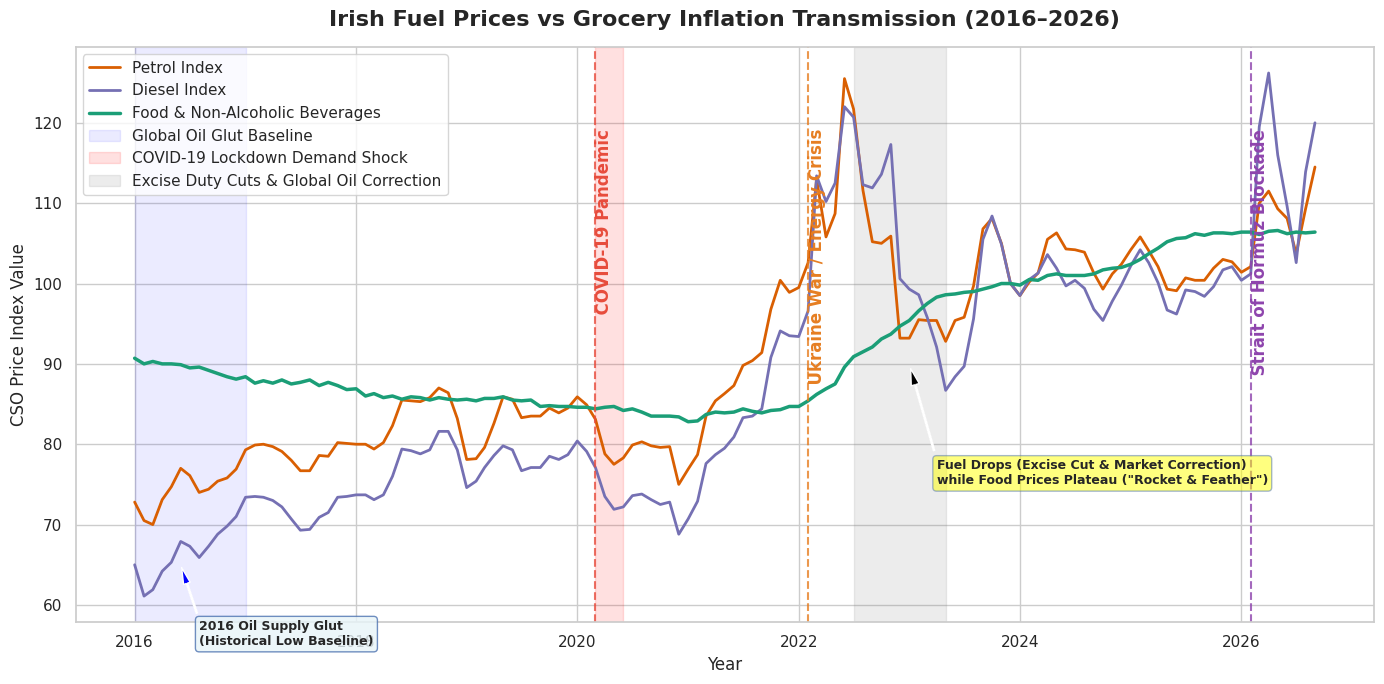

In [12]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.figure(figsize=(14, 7))

# 1. Plot Core Variables
plt.plot(
    df["Month_DT"],
    df["Petrol"],
    label="Petrol Index",
    color="#d95f02",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Diesel"],
    label="Diesel Index",
    color="#7570b3",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Food and non-alcoholic beverages"],
    label="Food & Non-Alcoholic Beverages",
    color="#1b9e77",
    linewidth=2.5,
)

# 2. Shaded Event Spans (Highlighting key price periods)
plt.axvspan(
    pd.to_datetime("2016-01-01"),
    pd.to_datetime("2017-01-01"),
    color="blue",
    alpha=0.08,
    label="Global Oil Glut Baseline",
)
plt.axvspan(
    pd.to_datetime("2020-03-01"),
    pd.to_datetime("2020-06-01"),
    color="red",
    alpha=0.12,
    label="COVID-19 Lockdown Demand Shock",
)
plt.axvspan(
    pd.to_datetime("2022-07-01"),
    pd.to_datetime("2023-05-01"),
    color="gray",
    alpha=0.15,
    label="Excise Duty Cuts & Global Oil Correction",
)

# 3. Geopolitical Shock Milestone Lines
events = [
    ("2020-03-01", "COVID-19 Pandemic", "#e74c3c"),
    ("2022-02-01", "Ukraine War / Energy Crisis", "#e67e22"),
    ("2026-02-01", "Strait of Hormuz Blockade", "#8e44ad"),
]

for date_str, label, col in events:
    event_date = pd.to_datetime(date_str)
    plt.axvline(
        x=event_date, color=col, linestyle="--", alpha=0.8, linewidth=1.5
    )
    plt.text(
        event_date,
        df["Petrol"].max() * 0.95,
        f"  {label}",
        color=col,
        fontweight="bold",
        rotation=90,
        verticalalignment="top",
    )

# 4. Text Annotations
plt.annotate(
    "2016 Oil Supply Glut\n(Historical Low Baseline)",
    xy=(pd.to_datetime("2016-06-01"), 65),
    xytext=(pd.to_datetime("2016-08-01"), 55),
    arrowprops=dict(facecolor="blue", shrink=0.05, width=1, headwidth=5),
    fontweight="bold",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="#e8f4f8", ec="b", lw=1, alpha=0.8),
)

plt.annotate(
    'Fuel Drops (Excise Cut & Market Correction)\nwhile Food Prices Plateau ("Rocket & Feather")',
    xy=(pd.to_datetime("2023-01-01"), 90),
    xytext=(pd.to_datetime("2023-04-01"), 75),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontweight="bold",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="b", lw=1, alpha=0.5),
)

# 5. Graph Formatting
plt.title(
    "Irish Fuel Prices vs Grocery Inflation Transmission (2016–2026)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("CSO Price Index Value", fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()

plt.show()

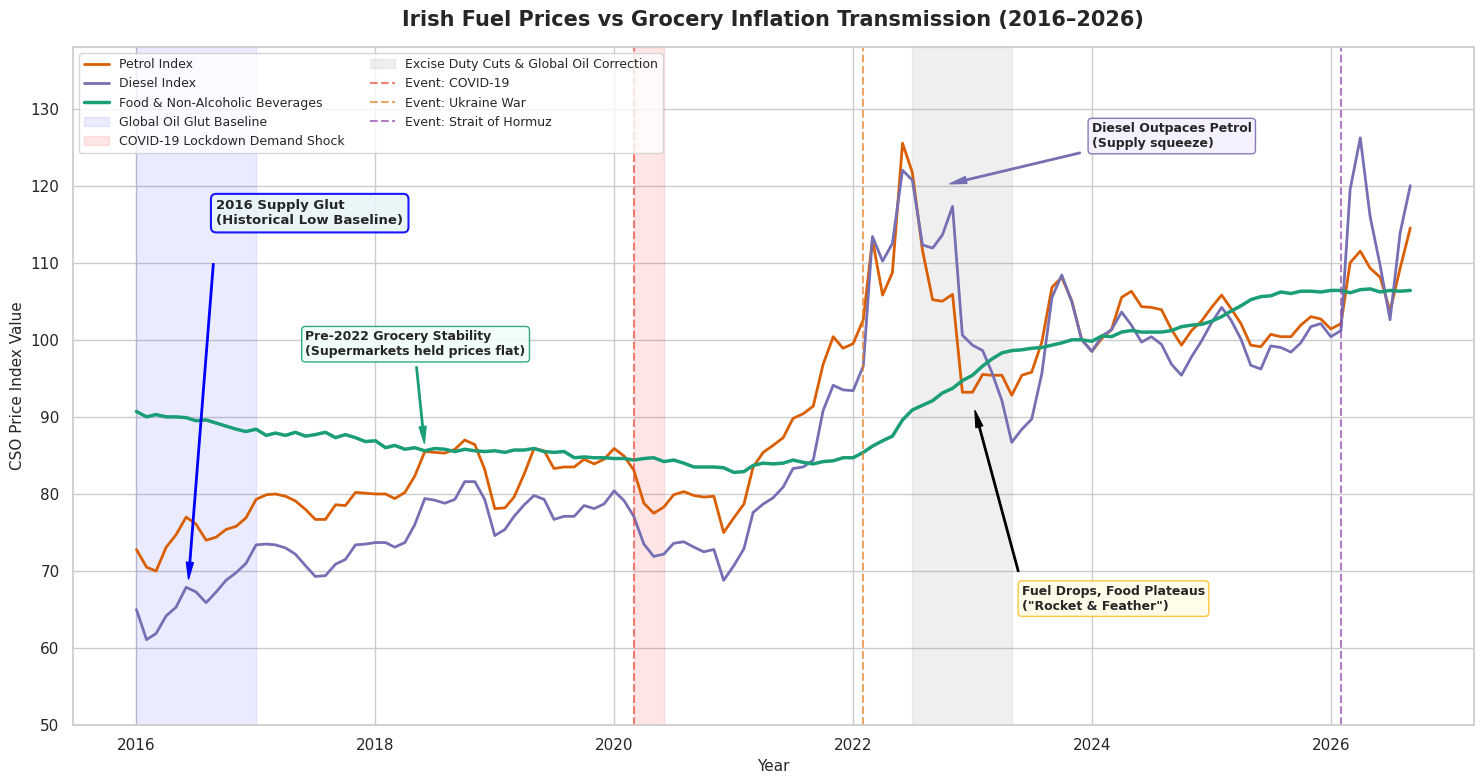

In [18]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.figure(figsize=(15, 8))

# 1. Plot Core Lines
plt.plot(
    df["Month_DT"],
    df["Petrol"],
    label="Petrol Index",
    color="#d95f02",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Diesel"],
    label="Diesel Index",
    color="#7570b3",
    linewidth=2,
)
plt.plot(
    df["Month_DT"],
    df["Food and non-alcoholic beverages"],
    label="Food & Non-Alcoholic Beverages",
    color="#1b9e77",
    linewidth=2.5,
)

# 2. Shaded Event Spans
plt.axvspan(
    pd.to_datetime("2016-01-01"),
    pd.to_datetime("2017-01-01"),
    color="blue",
    alpha=0.08,
    label="Global Oil Glut Baseline",
)
plt.axvspan(
    pd.to_datetime("2020-03-01"),
    pd.to_datetime("2020-06-01"),
    color="red",
    alpha=0.10,
    label="COVID-19 Lockdown Demand Shock",
)
plt.axvspan(
    pd.to_datetime("2022-07-01"),
    pd.to_datetime("2023-05-01"),
    color="gray",
    alpha=0.12,
    label="Excise Duty Cuts & Global Oil Correction",
)

# 3. Event Lines
events = [
    ("2020-03-01", "COVID-19", "#e74c3c"),
    ("2022-02-01", "Ukraine War", "#e67e22"),
    ("2026-02-01", "Strait of Hormuz", "#8e44ad"),
]

for date_str, label, col in events:
    event_date = pd.to_datetime(date_str)
    plt.axvline(
        x=event_date,
        color=col,
        linestyle="--",
        alpha=0.7,
        linewidth=1.5,
        label=f"Event: {label}",
    )

# 4. Annotations

# 2016 Supply Glut
plt.annotate(
    "2016 Supply Glut\n(Historical Low Baseline)",
    xy=(pd.to_datetime("2016-06-01"), 65),
    xytext=(pd.to_datetime("2016-09-01"), 115),
    arrowprops=dict(
        facecolor="blue",
        edgecolor="blue",
        shrink=0.08,
        width=1,
        headwidth=5,
    ),
    fontweight="bold",
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.4", fc="#e8f4f8", ec="blue", lw=1.5, alpha=0.9
    ),
)

# Pre-2022 Stability
plt.annotate(
    "Pre-2022 Grocery Stability\n(Supermarkets held prices flat)",
    xy=(pd.to_datetime("2018-06-01"), 86),
    xytext=(pd.to_datetime("2017-06-01"), 98),
    arrowprops=dict(
        facecolor="#1b9e77",
        edgecolor="#1b9e77",
        shrink=0.05,
        width=1,
        headwidth=5,
    ),
    fontweight="bold",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.3", fc="#f0fff8", ec="#1b9e77", lw=1, alpha=0.9
    ),
)

# MOVED TO THE RIGHT: Diesel Outpaces Petrol box shifted to the open space around 2024–2025
plt.annotate(
    "Diesel Outpaces Petrol\n(Supply squeeze)",
    xy=(pd.to_datetime("2022-10-01"), 120),
    xytext=(pd.to_datetime("2024-01-01"), 125),
    arrowprops=dict(
        facecolor="#7570b3",
        edgecolor="#7570b3",
        shrink=0.05,
        width=1,
        headwidth=5,
    ),
    fontweight="bold",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.3", fc="#f5f0ff", ec="#7570b3", lw=1, alpha=0.9
    ),
)

# Rocket & Feather
plt.annotate(
    'Fuel Drops, Food Plateaus\n("Rocket & Feather")',
    xy=(pd.to_datetime("2023-01-01"), 92),
    xytext=(pd.to_datetime("2023-06-01"), 65),
    arrowprops=dict(
        facecolor="black", edgecolor="black", shrink=0.05, width=1, headwidth=5
    ),
    fontweight="bold",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.3", fc="#fffde7", ec="#fbc02d", lw=1, alpha=0.9
    ),
)

# 5. Graph Formatting
plt.title(
    "Irish Fuel Prices vs Grocery Inflation Transmission (2016–2026)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year", fontsize=11)
plt.ylabel("CSO Price Index Value", fontsize=11)
plt.ylim(50, 138)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))

# Legend layout
plt.legend(loc="upper left", ncol=2, frameon=True, fontsize=9)
plt.tight_layout()

plt.show()